# Notebook 03: Dự đoán khách hàng rời bỏ (churn)

**Mục tiêu của notebook:**

1. Xây dựng đặc trưng cho từng khách hàng, **chỉ từ dữ liệu giai đoạn quan sát** (trước 10/09/2011).
2. Huấn luyện và tinh chỉnh 4 mô hình phân lớp: **Logistic Regression** (mốc so sánh), **Decision Tree**, **Random Forest**, **XGBoost**.
3. Đánh giá trên tập test bằng Precision, Recall, F1, ROC-AUC, ma trận nhầm lẫn và đường ROC.
4. Giải thích mô hình tốt nhất: yếu tố nào khiến khách rời bỏ, cụm nào có nguy cơ cao nhất.
5. Xuất xác suất churn dự đoán của từng khách để dùng cho gợi ý sản phẩm ở notebook 04.

**Đầu vào:** `transactions_clean.csv`, `customers_clustered.csv`.
**Đầu ra:** `data/processed/churn_predictions.csv`.

**Bài toán:** phân lớp nhị phân, lớp dương là `churn = 1` (khách không mua gì trong giai đoạn 10/09/2011 đến 09/12/2011).

## 0. Khai báo thư viện và hằng số

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.inspection import permutation_importance

pd.set_option("display.float_format", "{:,.3f}".format)

RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
REF_DATE = pd.Timestamp("2011-09-10")  # features use only transactions before this date
CLUSTER_ORDER = ["VIP", "Khách mới", "Có nguy cơ", "Ngủ đông"]

In [2]:
# Shared chart style for every notebook (light surface, thin marks, recessive grid)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,  # negative numbers use the ASCII "-" instead of the Unicode minus sign
})


def save_fig(fig, filename):
    """Save a figure as PNG into the figures/ folder."""
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")


CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, COLORS[:4]))
CHURN_COLORS = {0: COLORS[0], 1: COLORS[1]}
MODEL_COLORS = dict(zip(["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"], COLORS[4:8]))

## 1. Đọc dữ liệu

In [3]:
transactions = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
customers = pd.read_csv(PROCESSED_DIR / "customers_clustered.csv").set_index("CustomerID")

# Observation period only: no information from the prediction period is used for features
obs = transactions[(transactions["InvoiceDate"] < REF_DATE) & transactions["CustomerID"].isin(customers.index)]
assert obs["InvoiceDate"].max() < REF_DATE

print(f"Số khách: {len(customers):,}")
print(f"Giao dịch giai đoạn quan sát: {len(obs):,} dòng, đến ngày {obs['InvoiceDate'].max():%d/%m/%Y}")
customers.head()

Số khách: 4,299
Giao dịch giai đoạn quan sát: 582,831 dòng, đến ngày 09/09/2011


,Recency,Frequency,Monetary,Cluster,ClusterName,churn
CustomerID,,,,,,
12347,39,6,"3,402.390",2,Có nguy cơ,0
12348,158,4,"1,388.400",2,Có nguy cơ,0
12349,317,2,"2,221.140",2,Có nguy cơ,0
12350,220,1,294.400,3,Ngủ đông,1
12351,285,1,300.930,3,Ngủ đông,1


## 2. Xây dựng đặc trưng

| Đặc trưng | Ý nghĩa |
|---|---|
| `Recency` | Số ngày từ lần mua cuối đến 10/09/2011 (lấy từ notebook 02) |
| `Frequency` | Số hóa đơn (lấy từ notebook 02) |
| `Monetary` | Tổng chi tiêu, GBP (lấy từ notebook 02) |
| `Tenure` | Thâm niên: số ngày từ lần mua **đầu tiên** đến 10/09/2011 |
| `AvgOrderValue` | Giá trị trung bình mỗi hóa đơn = `Monetary / Frequency` |
| `NumProducts` | Số sản phẩm khác nhau đã mua |
| `IsUK` | 1 nếu khách ở Anh, 0 nếu ở nước khác (lấy quốc gia xuất hiện nhiều nhất trong giao dịch của khách) |
| `Cluster_*` | Nhãn cụm RFM từ notebook 02, mã hóa one-hot |

Tất cả đặc trưng đều tính từ giao dịch **trước 10/09/2011**, nên không có rò rỉ dữ liệu từ giai đoạn dự đoán. Nhãn cụm cũng không gây rò rỉ nhãn, vì phân cụm ở notebook 02 không sử dụng biến `churn`.

In [4]:
extra = obs.groupby("CustomerID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    NumProducts=("StockCode", "nunique"),
    Country=("Country", lambda s: s.value_counts().index[0]),
)
extra["Tenure"] = (REF_DATE - extra["FirstPurchase"].dt.normalize()).dt.days

data = customers.join(extra[["Tenure", "NumProducts", "Country"]])
data["AvgOrderValue"] = data["Monetary"] / data["Frequency"]
data["IsUK"] = (data["Country"] == "United Kingdom").astype(int)

NUM_FEATURES = ["Recency", "Frequency", "Monetary", "Tenure", "AvgOrderValue", "NumProducts"]
print("Số giá trị thiếu:", data[NUM_FEATURES + ["IsUK", "ClusterName"]].isna().sum().sum())
data[NUM_FEATURES].describe().T

Số giá trị thiếu: 0


,count,mean,std,min,25%,50%,75%,max
Recency,"4,299.000",143.662,116.495,1.000,37.000,111.000,271.000,365.000
Frequency,"4,299.000",6.534,12.061,1.000,2.000,3.000,7.000,280.000
Monetary,"4,299.000","2,961.482","13,026.479",2.900,404.425,962.900,"2,439.775","454,922.090"
Tenure,"4,299.000",409.746,189.360,1.000,289.000,436.000,583.000,648.000
AvgOrderValue,"4,299.000",368.801,479.298,2.900,182.457,282.350,417.193,"12,425.450"
NumProducts,"4,299.000",84.394,111.928,1.000,22.000,50.000,106.000,"2,167.000"


### 2.1. So sánh đặc trưng giữa khách ở lại và khách rời bỏ

,Trung vị: ở lại (0),Trung vị: rời bỏ (1)
Recency,61.000,179.000
Frequency,5.000,2.000
Monetary,"1,675.730",610.450
Tenure,500.000,355.000
AvgOrderValue,303.762,255.622
NumProducts,75.000,34.000


,Số khách,Tỷ lệ churn
IsUK,,
Khác,384,0.469
UK,3915,0.495


Đã lưu: figures/03_dac_trung_theo_churn.png


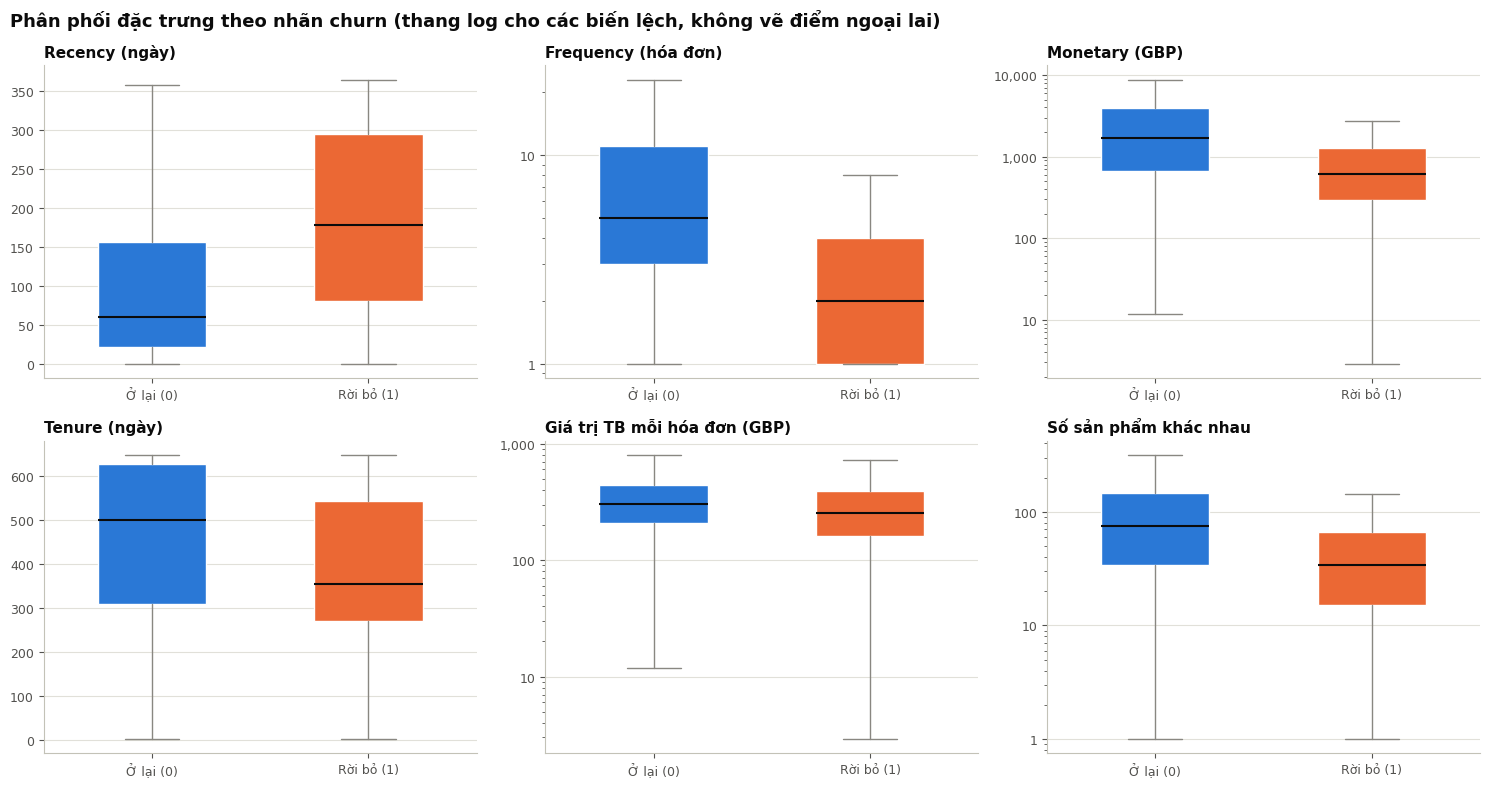

In [5]:
by_churn = data.groupby("churn")[NUM_FEATURES].median().T
by_churn.columns = ["Trung vị: ở lại (0)", "Trung vị: rời bỏ (1)"]
display(by_churn)

uk_churn = data.groupby(data["IsUK"].map({1: "UK", 0: "Khác"}))["churn"].agg(["size", "mean"])
uk_churn.columns = ["Số khách", "Tỷ lệ churn"]
display(uk_churn)

LABELS = {"Recency": "Recency (ngày)", "Frequency": "Frequency (hóa đơn)", "Monetary": "Monetary (GBP)",
          "Tenure": "Tenure (ngày)", "AvgOrderValue": "Giá trị TB mỗi hóa đơn (GBP)",
          "NumProducts": "Số sản phẩm khác nhau"}
LOG_SCALE = ["Frequency", "Monetary", "AvgOrderValue", "NumProducts"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    groups = [data.loc[data["churn"] == c, col] for c in (0, 1)]
    box = ax.boxplot(groups, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops=dict(color=INK, linewidth=1.5),
                     whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, c in zip(box["boxes"], (0, 1)):
        patch.set_facecolor(CHURN_COLORS[c])
        patch.set_edgecolor("white")
    ax.set_xticks([1, 2], ["Ở lại (0)", "Rời bỏ (1)"])
    ax.set_title(LABELS[col], fontsize=11)
    if col in LOG_SCALE:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.suptitle("Phân phối đặc trưng theo nhãn churn (thang log cho các biến lệch, không vẽ điểm ngoại lai)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_dac_trung_theo_churn.png")
plt.show()

**Nhận xét:** - Khách rời bỏ có **Recency cao hơn rõ rệt** (trung vị 179 so với 61 ngày), mua ít lần hơn (2 so với 5 hóa đơn), chi ít hơn (£610 so với £1.676), mua ít loại sản phẩm hơn (34 so với 75) và thâm niên ngắn hơn (355 so với 500 ngày).
- Giá trị trung bình mỗi hóa đơn khác biệt ít (£256 so với £304): khách rời bỏ không hẳn mua đơn nhỏ hơn, mà chủ yếu **mua thưa hơn**.
- Tỷ lệ churn ở Anh (49,5%) và ở các nước khác (46,9%) gần như bằng nhau, nên quốc gia nhiều khả năng không phải yếu tố quan trọng.
- Các hộp của hai nhóm chồng lấn nhau đáng kể: không một đặc trưng đơn lẻ nào tách được hai nhóm, cần kết hợp nhiều đặc trưng trong mô hình.

### 2.2. Ma trận đặc trưng

- Các biến lệch phải mạnh (`Frequency`, `Monetary`, `AvgOrderValue`, `NumProducts`) được biến đổi `log1p`. Phép biến đổi này tính riêng trên từng dòng nên không gây rò rỉ thông tin giữa tập train và test. Nó giúp Logistic Regression hoạt động tốt hơn, còn các mô hình cây thì không bị ảnh hưởng (cây chỉ quan tâm thứ tự giá trị).
- `ClusterName` được mã hóa one-hot thành 4 cột `Cluster_*`.

In [6]:
LOG_FEATURES = ["Frequency", "Monetary", "AvgOrderValue", "NumProducts"]

X = data[NUM_FEATURES].copy()
X[LOG_FEATURES] = np.log1p(X[LOG_FEATURES])
X["IsUK"] = data["IsUK"]
cluster_dummies = pd.get_dummies(data["ClusterName"], prefix="Cluster", dtype=int)
cluster_dummies = cluster_dummies[[f"Cluster_{name}" for name in CLUSTER_ORDER]]
cluster_dummies.columns = [c.replace(" ", "_") for c in cluster_dummies.columns]
X = pd.concat([X, cluster_dummies], axis=1)
y = data["churn"]

FEATURES = X.columns.tolist()
print("Các đặc trưng:", FEATURES)
X.head()

Các đặc trưng: ['Recency', 'Frequency', 'Monetary', 'Tenure', 'AvgOrderValue', 'NumProducts', 'IsUK', 'Cluster_VIP', 'Cluster_Khách_mới', 'Cluster_Có_nguy_cơ', 'Cluster_Ngủ_đông']


,Recency,Frequency,Monetary,Tenure,AvgOrderValue,NumProducts,IsUK,Cluster_VIP,Cluster_Khách_mới,Cluster_Có_nguy_cơ,Cluster_Ngủ_đông
CustomerID,,,,,,,,,,,
12347,39,1.946,8.133,314,6.342,4.682,0,0,0,1,0
12348,158,1.609,7.237,348,5.852,3.219,0,0,0,1,0
12349,317,1.099,7.706,499,7.014,4.500,0,0,0,1,0
12350,220,0.693,5.688,220,5.688,2.833,0,0,0,0,1
12351,285,0.693,5.710,285,5.710,3.091,0,0,0,0,1


## 3. Chia tập train/test

Chia 80/20 với `stratify=churn` để tỷ lệ churn ở hai tập như nhau. Tập test được giữ riêng, **chỉ dùng một lần** ở bước đánh giá cuối cùng.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} khách, tỷ lệ churn = {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} khách, tỷ lệ churn = {y_test.mean():.1%}")

Train: 3,439 khách, tỷ lệ churn = 49.2%
Test:  860 khách, tỷ lệ churn = 49.2%


**Về mất cân bằng lớp:** tỷ lệ churn khoảng 49%, hai lớp gần như cân bằng. Vì vậy **không cần** dùng SMOTE hay `class_weight="balanced"`: các kỹ thuật này dành cho trường hợp lớp thiểu số chiếm tỷ lệ nhỏ (ví dụ dưới 20 đến 30%), còn ở đây chúng hầu như không thay đổi kết quả mà chỉ làm quy trình phức tạp hơn.

## 4. Huấn luyện và tinh chỉnh mô hình

- Mỗi mô hình được tinh chỉnh bằng **GridSearchCV** với lưới tham số nhỏ, **5-fold Stratified Cross-Validation trên tập train**, tiêu chí chọn là **ROC-AUC**.
- Logistic Regression cần chuẩn hóa dữ liệu. `StandardScaler` được đặt **bên trong Pipeline**, nên trong mỗi fold scaler chỉ được fit trên phần train của fold đó, và ở lần fit cuối chỉ fit trên tập train, không bao giờ nhìn thấy tập test.
- Các mô hình cây (Decision Tree, Random Forest, XGBoost) không cần chuẩn hóa.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]),
        {"model__C": [0.01, 0.1, 1, 10, 100]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [10, 30, 50]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
        {"max_depth": [4, 6, 8, None], "min_samples_leaf": [5, 20]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
        {"n_estimators": [100, 300], "max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1]},
    ),
}

best_models = {}
cv_rows = []
for name, (estimator, param_grid) in models.items():
    search = GridSearchCV(estimator, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    cv_rows.append({
        "Mô hình": name,
        "Tham số tốt nhất": search.best_params_,
        "ROC-AUC CV (TB)": search.best_score_,
        "ROC-AUC CV (độ lệch chuẩn)": search.cv_results_["std_test_score"][search.best_index_],
    })
    print(f"{name:20s} ROC-AUC CV = {search.best_score_:.4f}  {search.best_params_}")

cv_results = pd.DataFrame(cv_rows).set_index("Mô hình")
cv_results

Logistic Regression  ROC-AUC CV = 0.7684  {'model__C': 1}


Decision Tree        ROC-AUC CV = 0.7567  {'max_depth': 6, 'min_samples_leaf': 50}


Random Forest        ROC-AUC CV = 0.7692  {'max_depth': 6, 'min_samples_leaf': 5}


XGBoost              ROC-AUC CV = 0.7712  {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}


,Tham số tốt nhất,ROC-AUC CV (TB),ROC-AUC CV (độ lệch chuẩn)
Mô hình,,,
Logistic Regression,{'model__C': 1},0.768,0.011
Decision Tree,"{'max_depth': 6, 'min_samples_leaf': 50}",0.757,0.017
Random Forest,"{'max_depth': 6, 'min_samples_leaf': 5}",0.769,0.013
XGBoost,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",0.771,0.013


## 5. Đánh giá trên tập test

Ngưỡng phân lớp mặc định là 0,5: khách có xác suất churn dự đoán ≥ 0,5 được xếp vào nhóm rời bỏ.

- **Precision:** trong số khách bị dự đoán rời bỏ, bao nhiêu % thực sự rời bỏ (tránh lãng phí ngân sách giữ chân).
- **Recall:** trong số khách thực sự rời bỏ, mô hình phát hiện được bao nhiêu % (tránh bỏ sót khách cần giữ).
- **F1:** trung bình điều hòa của Precision và Recall.
- **ROC-AUC:** khả năng xếp hạng khách rời bỏ cao hơn khách ở lại, không phụ thuộc ngưỡng.

In [9]:
test_proba = {}
test_rows = []
for name, model in best_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    test_proba[name] = proba
    test_rows.append({
        "Mô hình": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

comparison = pd.DataFrame(test_rows).set_index("Mô hình")
comparison.insert(0, "ROC-AUC CV", cv_results["ROC-AUC CV (TB)"])
comparison.style.format("{:.3f}").highlight_max(color="#cde2fb")

,ROC-AUC CV,Accuracy,Precision,Recall,F1,ROC-AUC
Mô hình,,,,,,
Logistic Regression,0.768,0.666,0.655,0.681,0.667,0.729
Decision Tree,0.757,0.681,0.664,0.714,0.688,0.720
Random Forest,0.769,0.667,0.657,0.678,0.667,0.732
XGBoost,0.771,0.667,0.657,0.678,0.667,0.730


In [10]:
# Model selection uses the cross-validation score, not the test score
best_name = cv_results["ROC-AUC CV (TB)"].idxmax()
best_model = best_models[best_name]
print(f"Mô hình được chọn (ROC-AUC CV cao nhất): {best_name}")

Mô hình được chọn (ROC-AUC CV cao nhất): XGBoost


**Lưu ý phương pháp:** mô hình tốt nhất được chọn theo **ROC-AUC trung bình trên cross-validation**, không theo kết quả trên tập test. Nếu chọn theo tập test, tập test sẽ gián tiếp tham gia vào quá trình chọn mô hình và kết quả báo cáo sẽ lạc quan hơn thực tế.

### 5.1. Ma trận nhầm lẫn

Đã lưu: figures/03_ma_tran_nham_lan.png


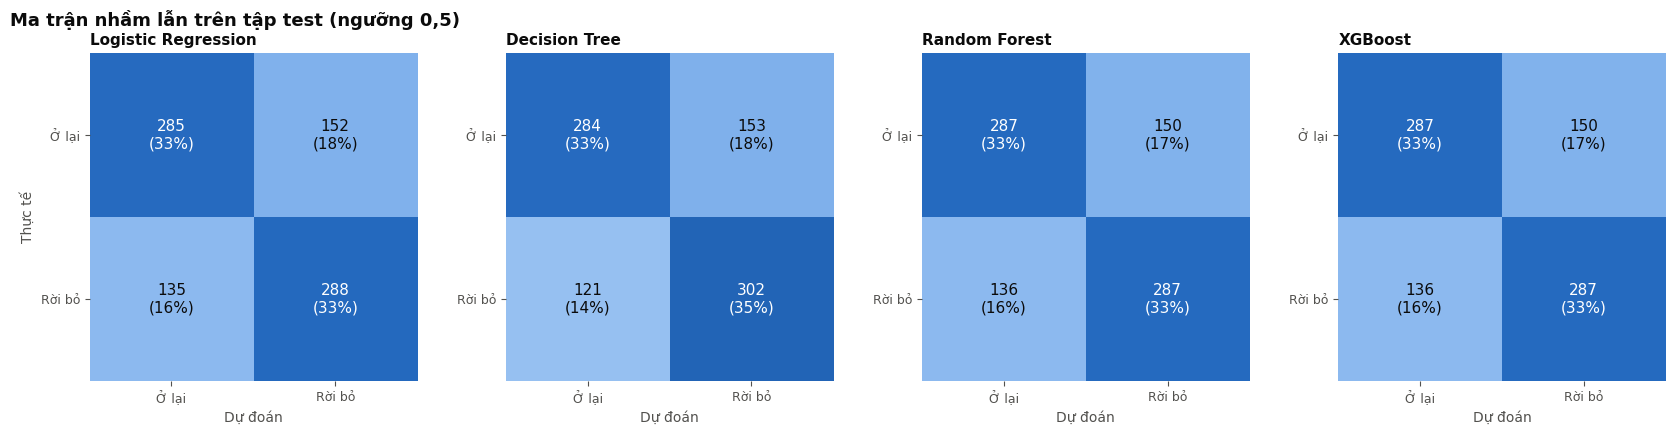

In [11]:
cm_cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fe", "#86b6ef", "#256abf", "#0d366b"])

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, name in zip(axes, best_models):
    pred = (test_proba[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap=cm_cmap, vmin=0, vmax=len(y_test) / 2)
    for i in range(2):
        for j in range(2):
            value = cm[i, j]
            text_color = "white" if value > len(y_test) / 4 else INK
            ax.text(j, i, f"{value}\n({value / len(y_test):.0%})", ha="center", va="center",
                    fontsize=11, color=text_color)
    ax.set_xticks([0, 1], ["Ở lại", "Rời bỏ"])
    ax.set_yticks([0, 1], ["Ở lại", "Rời bỏ"])
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế" if name == "Logistic Regression" else "")
    ax.set_title(name, fontsize=11)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("Ma trận nhầm lẫn trên tập test (ngưỡng 0,5)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_ma_tran_nham_lan.png")
plt.show()

### 5.2. Đường ROC

Đã lưu: figures/03_duong_roc.png


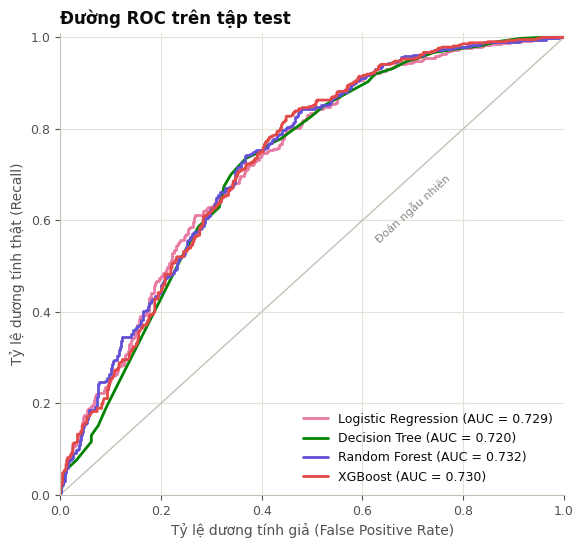

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
ax.text(0.62, 0.55, "Đoán ngẫu nhiên", rotation=42, fontsize=8, color=MUTED)
for name, proba in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.set_xlabel("Tỷ lệ dương tính giả (False Positive Rate)")
ax.set_ylabel("Tỷ lệ dương tính thật (Recall)")
ax.set_title("Đường ROC trên tập test")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right")
save_fig(fig, "03_duong_roc.png")
plt.show()

**Nhận xét kết quả các mô hình:** - Bốn mô hình cho kết quả **rất sát nhau**: ROC-AUC trên cross-validation từ 0,757 đến 0,771; trên tập test từ 0,720 đến 0,732; F1 từ 0,67 đến 0,69.
- XGBoost có ROC-AUC CV cao nhất (0,771) nên được chọn, nhưng chênh lệch với Random Forest (0,769) và Logistic Regression (0,768) nhỏ hơn độ lệch chuẩn giữa các fold (khoảng 0,013), nên **không có ý nghĩa thống kê**. Việc Logistic Regression đơn giản gần như ngang các mô hình phức tạp, và XGBoost tốt nhất chỉ dùng cây độ sâu 2, cho thấy quan hệ giữa đặc trưng và churn chủ yếu **đơn điệu** (càng lâu không mua càng dễ rời bỏ), không có nhiều tương tác phức tạp để mô hình cây khai thác.
- ROC-AUC trên test (khoảng 0,73) thấp hơn trên CV (khoảng 0,77) ở **cả 4 mô hình, kể cả Logistic Regression** vốn khó quá khớp. Vì vậy nguyên nhân chủ yếu là dao động do mẫu: tập test chỉ có 860 khách nên ROC-AUC ước lượng trên đó có thể lệch vài phần trăm. Có thể kết luận năng lực dự đoán thực tế nằm trong khoảng 0,73 đến 0,77.
- Ở ngưỡng 0,5: **Precision khoảng 0,66** (2/3 số khách bị cảnh báo thực sự rời bỏ) và **Recall khoảng 0,68 đến 0,71** (phát hiện được khoảng 70% khách rời bỏ). Decision Tree có Recall (0,714) và F1 (0,688) cao nhất ở ngưỡng này, nhưng ROC-AUC trên test thấp nhất (0,720), tức là xếp hạng khách theo nguy cơ kém hơn các mô hình còn lại.
- Mức ROC-AUC này là **khá**, phù hợp với độ khó của bài toán: khách sỉ mua hàng không đều đặn, và mô hình chỉ có lịch sử giao dịch, không có thông tin như khiếu nại, giá của đối thủ hay tình hình kinh doanh của khách.

## 6. Giải thích mô hình

### 6.1. Cây quyết định: quy tắc dễ đọc

Dù không phải mô hình tốt nhất, cây quyết định cho ra các quy tắc "nếu ... thì ..." rất dễ trình bày với bộ phận kinh doanh.

Cây ở mục 4 được huấn luyện trên các biến đã lấy `log1p`, nên ngưỡng tách nằm ở thang log và khó đọc. Vì phép log không làm đổi thứ tự giá trị, ta huấn luyện lại cây **với cùng tham số trên giá trị gốc** để có ngưỡng dễ hiểu (ví dụ "Frequency ≤ 6 hóa đơn"). Cách chia khách hàng của hai cây gần như trùng nhau (kiểm tra bằng tỷ lệ dự đoán giống nhau trên tập test).

Mỗi ô trong hình ghi: điều kiện tách, `samples` = tỷ lệ khách (trong tập train) rơi vào ô, `value` = [tỷ lệ ở lại, tỷ lệ rời bỏ], `class` = lớp chiếm đa số.

Tỷ lệ dự đoán giống nhau trên tập test giữa cây (giá trị gốc) và cây (log): 100.0%


Đã lưu: figures/03_cay_quyet_dinh.png


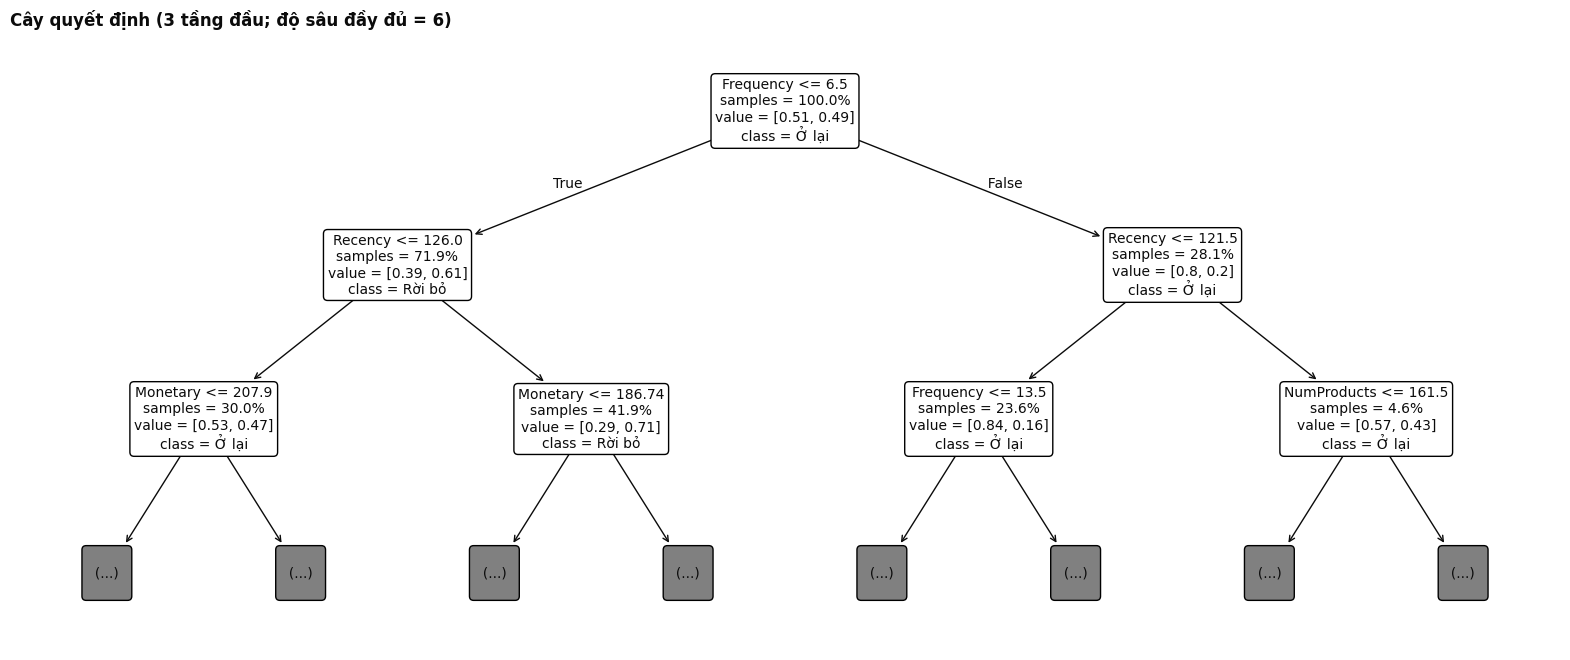

In [13]:
# Same hyperparameters, refit on original-scale features so that thresholds are easy to read
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()
X_train_raw[LOG_FEATURES] = data.loc[X_train.index, LOG_FEATURES]
X_test_raw[LOG_FEATURES] = data.loc[X_test.index, LOG_FEATURES]
tree = DecisionTreeClassifier(**best_models["Decision Tree"].get_params()).fit(X_train_raw, y_train)

agreement = (tree.predict(X_test_raw) == best_models["Decision Tree"].predict(X_test)).mean()
print(f"Tỷ lệ dự đoán giống nhau trên tập test giữa cây (giá trị gốc) và cây (log): {agreement:.1%}")

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, max_depth=2, feature_names=FEATURES, class_names=["Ở lại", "Rời bỏ"],
          filled=False, rounded=True, proportion=True, impurity=False, precision=2, fontsize=10, ax=ax)
ax.set_title(f"Cây quyết định (3 tầng đầu; độ sâu đầy đủ = {tree.get_depth()})")
save_fig(fig, "03_cay_quyet_dinh.png")
plt.show()

**Nhận xét:** Ba tầng đầu của cây cho ra các quy tắc dễ hiểu:

- **Điều kiện tách đầu tiên là số lần mua**: 72% khách mua không quá 6 lần, nhóm này có tỷ lệ rời bỏ 61%; khách mua từ 7 lần trở lên chỉ rời bỏ 20%.
- Trong cả hai nhánh, điều kiện tiếp theo đều là **Recency khoảng 4 tháng** (121 đến 126 ngày):
  - Khách mua ít (≤ 6 lần) **và** đã hơn 126 ngày không mua: tỷ lệ rời bỏ **71%** (chiếm 42% số khách). Nếu tổng chi tiêu của họ còn thấp (≤ £187) thì tỷ lệ rời bỏ lên tới 90%.
  - Khách thân thiết (≥ 7 lần) nhưng đã hơn 121 ngày không mua: tỷ lệ rời bỏ 43%, **gần gấp 3** so với khách thân thiết vẫn còn mua đều (16%).
- Quy tắc thực hành rút ra cho bộ phận kinh doanh: **khoảng 4 tháng không phát sinh đơn hàng là thời điểm nên chủ động liên hệ khách**, đặc biệt với các khách từng mua thường xuyên.

### 6.2. Mức độ quan trọng của đặc trưng (Permutation Importance)

Với mô hình tốt nhất, ta dùng **permutation importance trên tập test**: xáo trộn ngẫu nhiên giá trị của một đặc trưng rồi đo ROC-AUC giảm bao nhiêu. Đặc trưng càng quan trọng thì ROC-AUC giảm càng nhiều. Cách này áp dụng được cho mọi loại mô hình và đo trên dữ liệu mô hình chưa từng thấy.

Đã lưu: figures/03_feature_importance.png


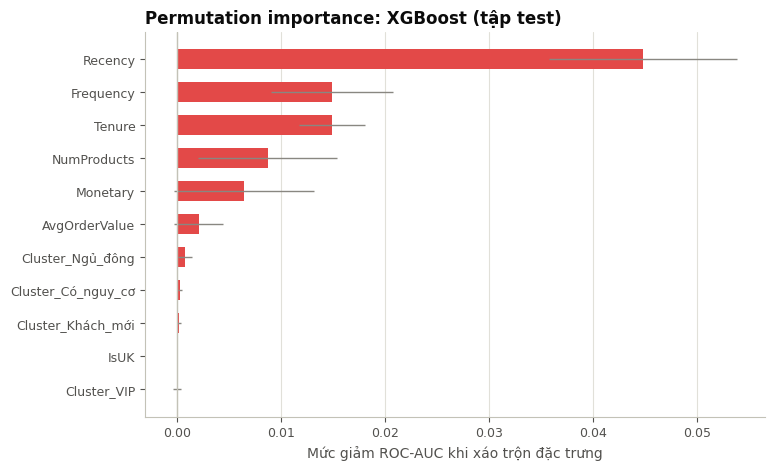

,Mức giảm ROC-AUC (TB),Độ lệch chuẩn
Recency,0.045,0.009
Frequency,0.015,0.006
Tenure,0.015,0.003
NumProducts,0.009,0.007
Monetary,0.006,0.007
AvgOrderValue,0.002,0.002
Cluster_Ngủ_đông,0.001,0.001
Cluster_Có_nguy_cơ,0.000,0.000
Cluster_Khách_mới,0.000,0.000
IsUK,0.000,0.000


In [14]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({
    "Mức giảm ROC-AUC (TB)": perm.importances_mean,
    "Độ lệch chuẩn": perm.importances_std,
}, index=FEATURES).sort_values("Mức giảm ROC-AUC (TB)", ascending=False)

plot_data = importance.sort_values("Mức giảm ROC-AUC (TB)")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data.index, plot_data["Mức giảm ROC-AUC (TB)"], xerr=plot_data["Độ lệch chuẩn"],
        height=0.6, color=MODEL_COLORS[best_name], error_kw=dict(ecolor=MUTED, lw=1))
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("Mức giảm ROC-AUC khi xáo trộn đặc trưng")
ax.set_title(f"Permutation importance: {best_name} (tập test)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
save_fig(fig, "03_feature_importance.png")
plt.show()
importance

### 6.3. SHAP: chiều tác động của từng đặc trưng

Permutation importance cho biết đặc trưng nào quan trọng nhưng không cho biết **chiều tác động**. Biểu đồ SHAP (beeswarm) bổ sung điều này: mỗi chấm là một khách hàng trong tập test, trục ngang là mức đóng góp của đặc trưng vào dự đoán (dương: đẩy về phía **rời bỏ**, âm: đẩy về phía **ở lại**), màu thể hiện giá trị đặc trưng (đỏ: cao, xanh: thấp).

Đã lưu: figures/03_shap_summary.png


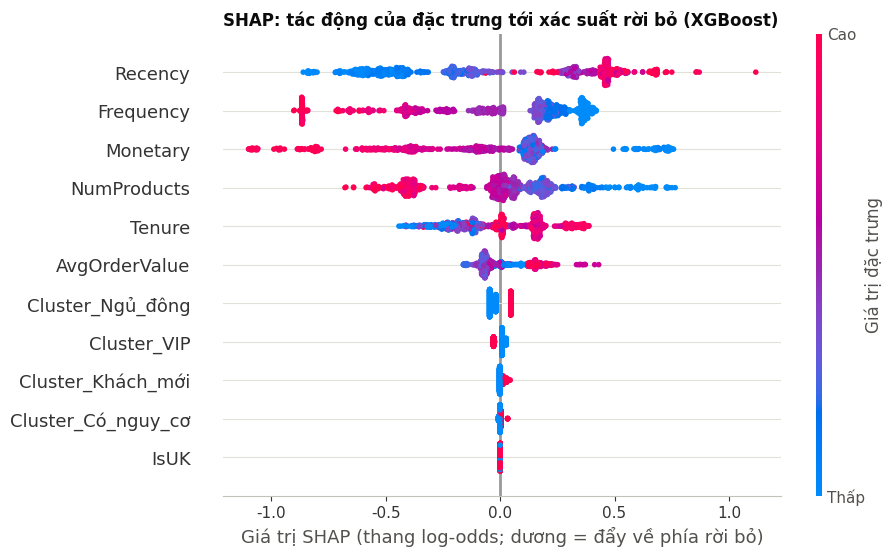

In [15]:
if best_name == "XGBoost":
    # shap 0.49 cannot read models from xgboost >= 3.1, so use XGBoost's built-in TreeSHAP.
    # pred_contribs=True returns one SHAP value per feature (log-odds scale) plus a bias column at the end.
    contribs = best_model.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)
    shap_values = shap.Explanation(values=contribs[:, :-1], base_values=contribs[:, -1],
                                   data=X_test.to_numpy(), feature_names=FEATURES)
else:
    shap_values = shap.TreeExplainer(best_model)(X_test)
    if shap_values.values.ndim == 3:  # some tree models return one set of values per class
        shap_values = shap_values[:, :, 1]

shap.plots.beeswarm(shap_values, max_display=len(FEATURES), show=False)
fig = plt.gcf()
fig.set_size_inches(9, 6)
fig.axes[0].set_xlabel("Giá trị SHAP (thang log-odds; dương = đẩy về phía rời bỏ)")
colorbar_ax = fig.axes[-1]
colorbar_ax.set_ylabel("Giá trị đặc trưng")
colorbar_ax.set_yticks(colorbar_ax.get_yticks(), ["Thấp", "Cao"])
plt.title(f"SHAP: tác động của đặc trưng tới xác suất rời bỏ ({best_name})", loc="left",
          fontsize=12, fontweight="bold")
save_fig(fig, "03_shap_summary.png")
plt.show()

### 6.4. Hệ số Logistic Regression

Logistic Regression là mô hình tuyến tính nên hệ số của nó (trên dữ liệu đã chuẩn hóa) cũng cho biết chiều tác động: hệ số dương làm tăng xác suất rời bỏ, hệ số âm làm giảm. Đây là cách kiểm tra chéo với SHAP.

In [16]:
lr = best_models["Logistic Regression"].named_steps["model"]
coefs = pd.Series(lr.coef_[0], index=FEATURES, name="Hệ số (dữ liệu đã chuẩn hóa)")
coefs.reindex(coefs.abs().sort_values(ascending=False).index).to_frame()

,Hệ số (dữ liệu đã chuẩn hóa)
Frequency,-0.739
Tenure,0.334
NumProducts,-0.299
Monetary,-0.273
Recency,0.268
Cluster_Có_nguy_cơ,0.079
Cluster_Khách_mới,-0.053
Cluster_VIP,-0.045
AvgOrderValue,-0.021
IsUK,-0.008


**Nhận xét về các yếu tố khiến khách rời bỏ:** 1. **Recency là yếu tố quan trọng nhất**: ROC-AUC giảm 0,045 khi xáo trộn, gấp khoảng 3 lần đặc trưng đứng thứ hai. Trên biểu đồ SHAP, Recency cao (màu đỏ) đẩy mạnh dự đoán về phía rời bỏ. Khách đã lâu không mua là dấu hiệu rõ nhất.
2. **Mức độ gắn bó (Frequency, Monetary, NumProducts)**: mua nhiều lần, chi nhiều, mua nhiều loại sản phẩm đều làm giảm nguy cơ rời bỏ (SHAP âm khi giá trị cao, hệ số Logistic Regression âm, lớn nhất là Frequency với -0,74). Ba biến này tương quan mạnh với nhau nên "chia sẻ" mức quan trọng, vì vậy permutation importance của từng biến riêng lẻ trông khá nhỏ.
3. **Tenure tác động ngược với trực giác**: nhìn riêng thì khách ở lại có thâm niên cao hơn, nhưng **khi các yếu tố khác như nhau**, thâm niên dài hơn lại làm **tăng** nguy cơ (SHAP dương khi Tenure cao, hệ số Logistic Regression +0,33). Giải thích: với cùng số hóa đơn, khách có thâm niên dài hơn nghĩa là **mua thưa hơn**. Đây là gợi ý để thêm đặc trưng "tốc độ mua" (Frequency / Tenure) trong phiên bản sau.
4. **AvgOrderValue** tác động nhỏ: khi Monetary và Frequency như nhau, giá trị đơn cao hơi làm tăng nguy cơ, vì đó là kiểu khách mua lô lớn nhưng thưa, dễ không có đơn nào trong 3 tháng.
5. **Nhãn cụm và IsUK gần như không đóng góp** vào khả năng dự đoán. Nhãn cụm được tạo từ chính R, F, M vốn đã là đặc trưng của mô hình, nên không mang thêm thông tin mới; còn quốc gia không tạo ra khác biệt về tỷ lệ churn. Nhãn cụm vẫn có giá trị cho **diễn giải và xây dựng chiến lược** theo nhóm, nhưng không cải thiện độ chính xác.

## 7. Dự đoán cho toàn bộ khách hàng và nguy cơ theo cụm

Notebook 04 cần xác suất churn của **tất cả** khách hàng để chọn khách cần gợi ý sản phẩm. Nếu dùng mô hình đã huấn luyện trên tập train để dự đoán lại chính tập train, xác suất sẽ "đẹp" hơn thực tế (mô hình đã thấy các khách đó). Vì vậy:

- Với khách thuộc **tập train**: dùng dự đoán **out-of-fold** (`cross_val_predict`, 5 fold), tức mỗi khách được dự đoán bởi một mô hình không được huấn luyện trên khách đó.
- Với khách thuộc **tập test**: dùng dự đoán của mô hình tốt nhất đã huấn luyện trên toàn bộ tập train.

In [17]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
test_proba_best = test_proba[best_name]

predictions = pd.concat([
    pd.DataFrame({"CustomerID": X_train.index, "Set": "train", "churn_proba": oof_proba}),
    pd.DataFrame({"CustomerID": X_test.index, "Set": "test", "churn_proba": test_proba_best}),
], ignore_index=True)
predictions["churn_pred"] = (predictions["churn_proba"] >= 0.5).astype(int)
predictions = predictions.merge(data[["ClusterName", "churn"]], left_on="CustomerID", right_index=True)

print(f"ROC-AUC out-of-fold trên tập train: {roc_auc_score(y_train, oof_proba):.3f}")
print(f"ROC-AUC trên tập test:              {roc_auc_score(y_test, test_proba_best):.3f}")

ROC-AUC out-of-fold trên tập train: 0.770
ROC-AUC trên tập test:              0.730


In [18]:
risk_by_cluster = predictions.groupby("ClusterName").agg(
    NumCustomers=("CustomerID", "size"),
    ActualChurnRate=("churn", "mean"),
    MeanChurnProba=("churn_proba", "mean"),
    PredictedChurners=("churn_pred", "sum"),
).reindex(CLUSTER_ORDER)
risk_by_cluster["PredictedChurnRate"] = risk_by_cluster["PredictedChurners"] / risk_by_cluster["NumCustomers"]

# Model quality inside each cluster (test set only)
test_part = predictions[predictions["Set"] == "test"]
auc_in_cluster = {
    name: roc_auc_score(group["churn"], group["churn_proba"])
    for name, group in test_part.groupby("ClusterName")
}
risk_by_cluster["ROC-AUC test trong cụm"] = pd.Series(auc_in_cluster)

risk_by_cluster.rename(columns={
    "NumCustomers": "Số khách", "ActualChurnRate": "Tỷ lệ churn thực tế", "MeanChurnProba": "Xác suất churn TB",
    "PredictedChurners": "Số khách dự đoán rời bỏ", "PredictedChurnRate": "Tỷ lệ dự đoán rời bỏ",
}).style.format({"Số khách": "{:,}", "Số khách dự đoán rời bỏ": "{:,}", "Tỷ lệ churn thực tế": "{:.1%}",
                 "Xác suất churn TB": "{:.3f}", "Tỷ lệ dự đoán rời bỏ": "{:.1%}", "ROC-AUC test trong cụm": "{:.3f}"})

,Số khách,Tỷ lệ churn thực tế,Xác suất churn TB,Số khách dự đoán rời bỏ,Tỷ lệ dự đoán rời bỏ,ROC-AUC test trong cụm
ClusterName,,,,,,
VIP,790,14.1%,0.138,1,0.1%,0.750
Khách mới,563,42.3%,0.418,90,16.0%,0.657
Có nguy cơ,"1,410",47.5%,0.471,638,45.2%,0.638
Ngủ đông,"1,536",71.4%,0.718,"1,494",97.3%,0.547


Đã lưu: figures/03_xac_suat_churn_theo_cum.png


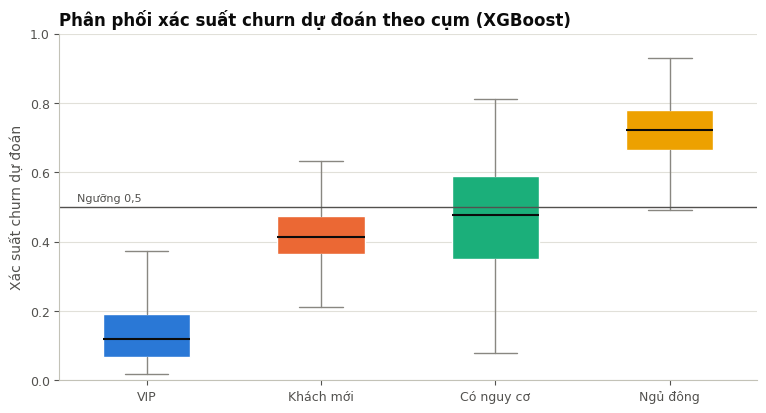

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
groups = [predictions.loc[predictions["ClusterName"] == name, "churn_proba"] for name in CLUSTER_ORDER]
box = ax.boxplot(groups, patch_artist=True, widths=0.5, showfliers=False,
                 medianprops=dict(color=INK, linewidth=1.5),
                 whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, name in zip(box["boxes"], CLUSTER_ORDER):
    patch.set_facecolor(CLUSTER_COLORS[name])
    patch.set_edgecolor("white")
ax.axhline(0.5, color=INK_2, linewidth=1)
ax.text(0.6, 0.51, "Ngưỡng 0,5", ha="left", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(range(1, 5), CLUSTER_ORDER)
ax.set_ylim(0, 1)
ax.set_ylabel("Xác suất churn dự đoán")
ax.set_title(f"Phân phối xác suất churn dự đoán theo cụm ({best_name})")
save_fig(fig, "03_xac_suat_churn_theo_cum.png")
plt.show()

**Nhận xét về nguy cơ theo cụm:** - Xác suất churn trung bình theo cụm **khớp rất sát** tỷ lệ thực tế (VIP 0,138 so với 14,1%; Khách mới 0,418 so với 42,3%; Có nguy cơ 0,471 so với 47,5%; Ngủ đông 0,718 so với 71,4%), tức mô hình được hiệu chỉnh (*calibrated*) tốt ở mức cụm.
- **Ngủ đông là cụm có nguy cơ cao nhất**: 97,3% khách bị dự đoán rời bỏ ở ngưỡng 0,5. Tuy nhiên ROC-AUC bên trong cụm chỉ 0,55: mô hình gần như không phân biệt được khách ngủ đông nào sẽ quay lại.
- **Có nguy cơ** có xác suất trải rộng nhất (từ khoảng 0,08 đến 0,81) và mô hình phân biệt khá bên trong cụm (ROC-AUC 0,64). Đây là nơi mô hình hữu ích nhất để chọn đúng khách cần giữ.
- **VIP**: ngưỡng 0,5 chỉ cảnh báo được **1 khách**, trong khi thực tế 14% khách VIP (khoảng 110 khách) đã rời bỏ. Nhưng ROC-AUC bên trong cụm VIP là 0,75, **cao nhất** trong 4 cụm: mô hình **xếp hạng** tốt các VIP theo nguy cơ, chỉ là xác suất tuyệt đối của họ đều thấp.
- **Hệ quả cho notebook 04:** dùng một ngưỡng chung 0,5 sẽ bỏ qua gần như toàn bộ VIP (nhóm mang lại 69% doanh thu) và dồn hết vào khách Ngủ đông có giá trị thấp. Vì vậy ở notebook 04, "khách có nguy cơ cao" sẽ được chọn **theo thứ hạng trong từng cụm**: nhóm 25% khách có xác suất churn cao nhất của mỗi cụm.

## 8. Xuất kết quả dự đoán

Các cột: `CustomerID`, `ClusterName`, `churn_proba` (xác suất churn dự đoán), `churn_pred` (nhãn dự đoán với ngưỡng 0,5), kèm `churn` (nhãn thực tế) và `Set` (khách thuộc tập train hay test) để tiện kiểm tra.

In [20]:
predictions = predictions[["CustomerID", "ClusterName", "churn_proba", "churn_pred", "churn", "Set"]]
predictions = predictions.sort_values("churn_proba", ascending=False)
predictions.to_csv(PROCESSED_DIR / "churn_predictions.csv", index=False, encoding="utf-8-sig")
print(predictions.shape)
predictions.head()

(4299, 6)


,CustomerID,ClusterName,churn_proba,churn_pred,churn,Set
1891,13254,Ngủ đông,0.930,1,1,train
3380,17532,Ngủ đông,0.930,1,1,train
86,14576,Ngủ đông,0.928,1,1,train
1622,17533,Ngủ đông,0.926,1,1,train
2746,13068,Ngủ đông,0.925,1,0,train


## 9. Tóm tắt

| Nội dung | Kết quả |
|---|---|
| Đặc trưng | Recency, Frequency, Monetary, Tenure, AvgOrderValue, NumProducts, IsUK, Cluster (one-hot); chỉ tính từ giai đoạn quan sát |
| Dữ liệu | 4.299 khách, churn 49,2% (cân bằng, không cần SMOTE); train 3.439 / test 860 |
| Mô hình được chọn | XGBoost (`max_depth=2`, `n_estimators=300`, `learning_rate=0.03`), ROC-AUC CV 0,771 |
| Kết quả test | ROC-AUC 0,730; Precision 0,657; Recall 0,678; F1 0,667. Bốn mô hình chênh lệch không đáng kể |
| Yếu tố chính | Recency (quan trọng nhất), sau đó Frequency, Tenure, NumProducts, Monetary. Nhãn cụm và quốc gia gần như không đóng góp thêm |
| Nguy cơ theo cụm | Ngủ đông (xác suất TB 0,72) > Có nguy cơ (0,47) > Khách mới (0,42) > VIP (0,14) |
| Lưu ý sử dụng | Ngưỡng 0,5 bỏ sót gần hết VIP rời bỏ, nên chọn khách cần giữ theo thứ hạng trong từng cụm |

File `churn_predictions.csv` chứa xác suất churn (out-of-fold cho tập train, dự đoán thường cho tập test) của cả 4.299 khách, dùng cho gợi ý sản phẩm ở notebook 04.